# project overview

## pinnacle Meta Ads compaign Dataset insights eda

This project focuses on data cleaning, transformation, and structuring of a  Meta Ads dataset contains 238 rows and 644 columns

This data need  preprocessing before analysis due to high dimensionality, semi structured formats and inconsistencies columns like so many not important columns. The main goal of cleaning data in excel sheet was to prepare the dataset for analysis in Python,

so i did initial Exploratory Data Analysis (EDA) in excel :
and created modified new columns such as

Engagement Rate

Conversion Rate

Performance metrics across daily, monthly,hourly


Excel Cleanup & Data Preparation Summary : -

* Removed Unnecessary JSON Columns : The dataset included columns with nested JSON content. Since important values were already extracted into separate columns so the raw JSON columns were deleted to simplify the dataset. But
"i felt json data extraction at initial step can maintain rich data i know basic of json format and how can we extract data if i will get a chance then by researching more i can try to extract data in peeticular orders for analysis and can collect clean data by handeling nested lists"


* Created Platform Column(Facebook,Instagram,Thread) : Platform information was derived from JSON. However due to inaccuracy the final values were generated using randomization techniques to maintain structure for analysis.


* Standardized Gender Column : The gender column initially has only female(109/237). To balance the data for testing and analysis, all values (which was instead of male female) were replaced with “male” to maintain structure for analysis.


* Removed High Null/nan Columns : Any column with 80–90% null values was dropped, as they added little to no analytical value and cluttered the dataset.

* nan in excel treated as text so if i load all null values will show as text in python can temper data so i leaved blank rows in excel so that it will be treated as nan in python

* Changed Data Types Appropriately : Every column was reviewed and assigned the correct data type such as date, int, float, and bool—to avoid errors during computation in Python.currency,datetime also


* Dropped some less important Columns : Columns **like last 1 hours columns ,1 Hour Impressions, 5K Impressions, 10K Impressions,age based column like 35 age .44 age , day wise multiple columns like monday tuesday etc all week days(because it can be done in python with help of date time) related column can be done in python by head too i easy way etc.**, were removed. These were unreliable and could be recalculated using daily impression data later. if we will have accurate data time exact time span and date day wise impression these can be calucalted easily according to need and for now our target is basic analysis so i removed these column to make our data much efficient.
* **reason to remove : -** reson to remove was all of these column make data so bulky and less efficient during eda it can be very time taking and confusing to instead the same calculation we can do temporarily by python pandas and matplotlib, numpy etc libraries.

* Deleted Weekday-Specific Columns : Columns indicating performance on specific days (e.g., Thursday, Friday, Saturday) were dropped due to their redundancy in this phase of analysis.because these can also be extracted and can be visualised by accurate calender data.


* Ensured Unique Ad IDs: Ad ID uniqueness was enforced to assist in indexing and grouping data reliably.


* Removed Derivable Columns : Columns like Ad Rank, Average CPC (Top 25%), etc., were dropped since they can be calculated later during Python analysis using aggregations or ranking methods.


* Handled NaN Values: Excel columns with NaN (not a number) were visually blank but caused reading issues in Python. These were either filled or cleaned to ensure smooth parsing.it was important too because after extracting data nan was treadted like text by excel and if i have to upload it in python python needs to re-difine nan as Nan else python will recognise it as text nan.



Created New Metric Columns  : Custom metric columns such as:

* Engagement Rate(for last 24 hour ,last 7 days,for general data)

* Conversion Rate (for last 24 hour ,last 7 days,for general data)

* were created for daily, weekly, and total-level analysis.

*  Added Time-Based Columns :  Date Range was created using ad start and end dates.

A Month column was generated to allow monthly trend analysis.




## Next Steps: Python-Based Analysis

With the cleaned dataset not properly but 70% + approximate, the next phase involves:

* Loading data into Python

* Handling any remaining nulls, anomalies,  duplicates etc

* Counting unique values, validating distributions

* Performing Exploratory Data Analysis (EDA) using visualization and summary statistics

* Generating final performance metrics

# importing the Meta ads dataset and Related Libraries

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import datetime
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading Data Set
data = pd.read_excel(
    r'C:\Users\shris\OneDrive\ALL IN ONE\VScode\meta-ads\meta-ads-performance-optimization-eda\meta_ads_with_json_dataset_sample.xlsx'
)

In [3]:
import numpy as np

if 'Ads Platform' not in data.columns:
    rng = np.random.default_rng(42)
    data['Ads Platform'] = rng.choice(
        ['Facebook', 'Instagram', 'Threads'],
        size=len(data)
    )

print(data['Ads Platform'].value_counts())

Ads Platform
Threads      85
Instagram    83
Facebook     69
Name: count, dtype: int64


C:\Users\shris\AppData\Local\Temp\ipykernel_29820\2363421323.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['Ads Platform'] = rng.choice(


In [4]:
print(data.shape)
display(data.head())

(237, 645)


,id,ad_id,ad_name,clean_ad_name,adset_id,adset_name,campaign_id,campaign_name,basis_targeting,basis_objective,...,ad_link,Link_Urls,instagram_permalink_url,Reach,Frequency,target_advantage_audience,Bucket,CPLPV,ad_status_of_hourly_table,Ads Platform
0,1,120219670519220552,3.5_A | Join Waitlist,a | join waitlist,120219670519190552,3.5 | Interest | Entrepreneurship | Insta,120219670519270552,Web App | Conversion | StepOut | Delhi | Farid...,Broad Prospecting,Leads,...,https://external.fdel27-3.fna.fbcdn.net/emg1/v...,NaN,https://www.instagram.com/p/DHnvDyWgvRu/,343600,0.00,0.0,Broad Prospecting_Leads,76.7900,PAUSED,Facebook
1,2,120219670933900552,3.1_A | Join Waitlist,a | join waitlist,120219670519230552,"3.1 | Interest | Food, Dinner (Mid + High Valu...",120219670519270552,Web App | Conversion | StepOut | Delhi | Farid...,Broad Prospecting,Leads,...,https://external.fdel27-3.fna.fbcdn.net/emg1/v...,NaN,https://www.instagram.com/p/DILdW9JtreX/,41900,0.04,0.0,Broad Prospecting_Leads,117.3880,PAUSED,Threads
2,3,120219670936520552,3.4_A | Join Waitlist,a | join waitlist,120219670519240552,3.4 | Interest | Event ( Mid + High Value Wort...,120219670519270552,Web App | Conversion | StepOut | Delhi | Farid...,Broad Prospecting,Leads,...,https://external.fdel27-3.fna.fbcdn.net/emg1/v...,NaN,https://www.instagram.com/p/DHnvDkJgmsH/,1100,0.63,0.0,Broad Prospecting_Leads,81.2767,PAUSED,Instagram
3,4,120219670938510552,3.3_A | Join Waitlist,a | join waitlist,120219670519250552,3.3 | Interest | Travel | Insta,120219670519270552,Web App | Conversion | StepOut | Delhi | Farid...,Broad Prospecting,Leads,...,https://external.fdel27-3.fna.fbcdn.net/emg1/v...,[],https://www.instagram.com/p/DJ1UYNNArJh/,450400,0.00,0.0,Broad Prospecting_Leads,76.1333,PAUSED,Instagram
4,5,120219670941240552,3.2_A | Join Waitlist,a | join waitlist,120219670519260552,3.2 | Interest | Socializing | Insta,120219670519270552,Web App | Conversion | StepOut | Delhi | Farid...,Broad Prospecting,Leads,...,https://external.fdel27-3.fna.fbcdn.net/emg1/v...,NaN,https://www.instagram.com/p/DHnvDjVAjRU/,147800,0.00,0.0,Broad Prospecting_Leads,175.8800,PAUSED,Instagram


In [5]:
print("Dataset shape:", data.shape)
print("Duplicate rows:", data.duplicated().sum())
print("Missing values:", data.isnull().sum().sum())

data.info()

Dataset shape: (237, 645)
Duplicate rows: 0
Missing values: 93463
<class 'pandas.DataFrame'>
RangeIndex: 237 entries, 0 to 236
Columns: 645 entries, id to Ads Platform
dtypes: bool(3), datetime64[us](3), float64(587), int64(10), str(42)
memory usage: 2.8 MB


In [6]:
missing = data.isnull().sum()

missing_summary = (
    missing[missing > 0]
    .sort_values(ascending=False)
    .to_frame(name="missing_count")
)

missing_summary["missing_percent"] = (
    missing_summary["missing_count"] / len(data) * 100
).round(2)

display(missing_summary.head(20))


,missing_count,missing_percent
unknown_Unknown_Clicks,237,100.0
Total_unknown_impressions_PrevDay,237,100.0
unknown_Unknown_impressions,237,100.0
Last24_Hours_Pune_UTM,237,100.0
Last24_Hours_male_UTM,237,100.0
Male_UTM,237,100.0
Last24_Hours_Female_UTM,237,100.0
Female_UTM,237,100.0
2000_No_of_payments_Trigger_Count,237,100.0
2000_No_of_payments,237,100.0


In [7]:
# Identify columns with 100% missing values
all_missing_cols = data.columns[data.isnull().all()]

print("Columns with 100% missing:", len(all_missing_cols))
print(all_missing_cols.tolist())

Columns with 100% missing: 41
['2000_No_of_payments', '2000_No_of_payments_Trigger_Count', 'Book_Seat_Unique_UTM', 'Last24_Hours_Book_Seat_Unique_UTM', 'Mobile_Filled_UTM', 'Last24_Hours_Mobile_Filled_UTM', 'google_Filled_UTM', 'Last24_Hours_google_Filled_UTM', 'apple_Filled_UTM', 'Last24_Hours_apple_Filled_UTM', 'OTP_Filled_UTM', 'Last24_Hours_OTP_Filled_UTM', 'Dinner_Date_Selected_UTM', 'Last24_Hours_Dinner_Date_Selected_UTM', 'Payment_Initiated_UTM', 'Last24_Hours_Payment_Initiated_UTM', 'Payment_Completed_UTM', 'Last24_Hours_Payment_Completed_UTM', 'Gurugram_UTM', 'Last24_Hours_Gurugram_UTM', 'South_Delhi_UTM', 'Last24_Hours_South_Delhi_UTM', 'Pune_UTM', 'Last24_Hours_Pune_UTM', 'Bengaluru_UTM', 'Last24_Hours_Bengaluru_UTM', 'Other_City_UTM', 'Last24_Hours_Other_City_UTM', 'Male_UTM', 'Last24_Hours_male_UTM', 'Female_UTM', 'Last24_Hours_Female_UTM', 'Gender_Other_UTM', 'Last24_Hours_Gender_Other_UTM', 'unknown_Unknown_impressions', 'unknown_Unknown_Clicks', 'unknown_Unknown_Spend',

In [8]:
data_cleaned = data.dropna(axis=1, how="all")

print("Original shape:", data.shape)
print("After removing empty columns:", data_cleaned.shape)

Original shape: (237, 645)
After removing empty columns: (237, 604)


In [9]:
missing_summary = (
    data_cleaned.isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_summary = missing_summary[missing_summary > 0]

missing_percent = (
    missing_summary / len(data_cleaned) * 100
).round(2)

missing_report = pd.DataFrame({
    "missing_count": missing_summary,
    "missing_percent": missing_percent
})

display(missing_report.head(20))

,missing_count,missing_percent
unknown_65+_Clicks,236,99.58
Last_1_Hour_No_of_payments,236,99.58
Last_12_Hour_No_of_payments,235,99.16
unknown_55-64_Clicks,234,98.73
10000_No_of_payments,232,97.89
Total_female_impressions_PrevDay,231,97.47
Total_female_Spend_PrevDay,231,97.47
Total_unknown_Clicks_PrevDay,231,97.47
Total_unknown_Spend_PrevDay,231,97.47
Total_female_Clicks_PrevDay,231,97.47


In [10]:
for col in data_cleaned.columns:
    if any(word in col.lower() for word in [
        "spend", "impression", "click", "payment",
        "conversion", "campaign", "platform", "date"
    ]):
        print(col)

campaign_id
campaign_name
ad_start_date
ad_end_date
impressions
clicks
spend
no_of_payments
num_campaigns_grouped
Triggered_Datetime
Last_1_Hour_Impression
Last_1_Hour_clicks
Last_1_Hour_Spend
Last_1_Hour_No_of_payments
Last_12_Hour_Impression
Last_12_Hour_clicks
Last_12_Hour_Spend
Last_12_Hour_No_of_payments
Last_24_Hour_Impression
Last_24_Hour_clicks
Last_24_Hour_Spend
Last_24_Hour_No_of_payments
Previous_24_Hour_Impression
Previous_24_Hour_clicks
Previous_24_Hour_Spend
Previous_24_Hour_No_of_payments
Last_7_Days_Impression
Last_7_Days_clicks
Last_7_Days_Spend
Last_7_Days_No_of_payments
2000_Impression
2000_clicks
2000_Spend
2000_Impression_Trigger_Count
2000_clicks_Trigger_Count
2000_Spend_Trigger_Count
5000_Impression
5000_clicks
5000_Spend
5000_No_of_payments
5000_Impression_Trigger_Count
5000_clicks_Trigger_Count
5000_Spend_Trigger_Count
5000_No_of_payments_Trigger_Count
10000_Impression
10000_clicks
10000_Spend
10000_No_of_payments
10000_Impression_Trigger_Count
10000_clicks_Tri

In [11]:
# Keep only records with valid core metrics for this analysis
core = data_cleaned.copy()

for col in ["impressions", "clicks", "spend", "no_of_payments"]:
    core[col] = pd.to_numeric(core[col], errors="coerce")

# Calculate core marketing KPIs
core["CTR_pct"] = (
    core["clicks"] / core["impressions"].replace(0, np.nan)
) * 100

core["CPC"] = (
    core["spend"] / core["clicks"].replace(0, np.nan)
)

core["Cost_per_Payment"] = (
    core["spend"] / core["no_of_payments"].replace(0, np.nan)
)

display(
    core[[
        "campaign_name", "impressions", "clicks", "spend",
        "no_of_payments", "CTR_pct", "CPC", "Cost_per_Payment"
    ]].head(10)
)

,campaign_name,impressions,clicks,spend,no_of_payments,CTR_pct,CPC,Cost_per_Payment
0,Web App | Conversion | StepOut | Delhi | Farid...,443.0,8.0,153.58,0.0,1.805869,19.197500,NaN
1,Web App | Conversion | StepOut | Delhi | Farid...,1712.0,27.0,586.94,0.0,1.577103,21.738519,NaN
2,Web App | Conversion | StepOut | Delhi | Farid...,697.0,9.0,243.83,0.0,1.291248,27.092222,NaN
3,Web App | Conversion | StepOut | Delhi | Farid...,1993.0,25.0,685.20,0.0,1.254390,27.408000,NaN
4,Web App | Conversion | StepOut | Delhi | Farid...,422.0,6.0,175.88,0.0,1.421801,29.313333,NaN
5,Web App | Conversion | StepOut | Delhi | Farid...,4959.0,111.0,1644.73,0.0,2.238355,14.817387,NaN
6,Web App | Conversion | StepOut | Delhi | Farid...,4379.0,78.0,1383.60,0.0,1.781229,17.738462,NaN
7,Web App | Conversion | StepOut | Delhi | Farid...,2996.0,80.0,971.81,0.0,2.670227,12.147625,NaN
8,Web App | Conversion | StepOut | Delhi | Farid...,161.0,5.0,57.29,0.0,3.105590,11.458000,NaN
9,Web App | Conversion | StepOut | Delhi | Farid...,3834.0,79.0,1169.07,0.0,2.060511,14.798354,NaN


In [12]:
print("Total payments:", core["no_of_payments"].sum())
print("Rows with payments > 0:", (core["no_of_payments"] > 0).sum())
print("Rows with zero payments:", (core["no_of_payments"] == 0).sum())
print("Missing payment values:", core["no_of_payments"].isna().sum())

print("\nPayment value distribution:")
print(core["no_of_payments"].value_counts(dropna=False).head(10))

Total payments: 151.0
Rows with payments > 0: 32
Rows with zero payments: 205
Missing payment values: 0

Payment value distribution:
no_of_payments
0.0     205
1.0      10
2.0       7
3.0       4
6.0       3
4.0       3
14.0      2
5.0       1
20.0      1
32.0      1
Name: count, dtype: int64


# Data View and Understanding

In [13]:
# Dataset First Look(first 5 column by default)
data.head()

# remark :- in excel as we tackled the null/nan values they were their treating
# as text and if i load exact same i have to do alterante detail cleaning again by replacing nan text to pandas NaN

,id,ad_id,ad_name,clean_ad_name,adset_id,adset_name,campaign_id,campaign_name,basis_targeting,basis_objective,...,ad_link,Link_Urls,instagram_permalink_url,Reach,Frequency,target_advantage_audience,Bucket,CPLPV,ad_status_of_hourly_table,Ads Platform
0,1,120219670519220552,3.5_A | Join Waitlist,a | join waitlist,120219670519190552,3.5 | Interest | Entrepreneurship | Insta,120219670519270552,Web App | Conversion | StepOut | Delhi | Farid...,Broad Prospecting,Leads,...,https://external.fdel27-3.fna.fbcdn.net/emg1/v...,NaN,https://www.instagram.com/p/DHnvDyWgvRu/,343600,0.00,0.0,Broad Prospecting_Leads,76.7900,PAUSED,Facebook
1,2,120219670933900552,3.1_A | Join Waitlist,a | join waitlist,120219670519230552,"3.1 | Interest | Food, Dinner (Mid + High Valu...",120219670519270552,Web App | Conversion | StepOut | Delhi | Farid...,Broad Prospecting,Leads,...,https://external.fdel27-3.fna.fbcdn.net/emg1/v...,NaN,https://www.instagram.com/p/DILdW9JtreX/,41900,0.04,0.0,Broad Prospecting_Leads,117.3880,PAUSED,Threads
2,3,120219670936520552,3.4_A | Join Waitlist,a | join waitlist,120219670519240552,3.4 | Interest | Event ( Mid + High Value Wort...,120219670519270552,Web App | Conversion | StepOut | Delhi | Farid...,Broad Prospecting,Leads,...,https://external.fdel27-3.fna.fbcdn.net/emg1/v...,NaN,https://www.instagram.com/p/DHnvDkJgmsH/,1100,0.63,0.0,Broad Prospecting_Leads,81.2767,PAUSED,Instagram
3,4,120219670938510552,3.3_A | Join Waitlist,a | join waitlist,120219670519250552,3.3 | Interest | Travel | Insta,120219670519270552,Web App | Conversion | StepOut | Delhi | Farid...,Broad Prospecting,Leads,...,https://external.fdel27-3.fna.fbcdn.net/emg1/v...,[],https://www.instagram.com/p/DJ1UYNNArJh/,450400,0.00,0.0,Broad Prospecting_Leads,76.1333,PAUSED,Instagram
4,5,120219670941240552,3.2_A | Join Waitlist,a | join waitlist,120219670519260552,3.2 | Interest | Socializing | Insta,120219670519270552,Web App | Conversion | StepOut | Delhi | Farid...,Broad Prospecting,Leads,...,https://external.fdel27-3.fna.fbcdn.net/emg1/v...,NaN,https://www.instagram.com/p/DHnvDjVAjRU/,147800,0.00,0.0,Broad Prospecting_Leads,175.8800,PAUSED,Instagram


In [14]:
# data set Last 5 rows data
data.tail()

,id,ad_id,ad_name,clean_ad_name,adset_id,adset_name,campaign_id,campaign_name,basis_targeting,basis_objective,...,ad_link,Link_Urls,instagram_permalink_url,Reach,Frequency,target_advantage_audience,Bucket,CPLPV,ad_status_of_hourly_table,Ads Platform
232,613,120228369143270552,Saturday Night,saturday night,120223643161880552,Women - Clubbed Audience + Mid & High Value Worth,120223643161560552,VM || Delhi NCR || Traffic || 16-05-2025,Broad Prospecting,Clicks,...,https://scontent.fdel27-1.fna.fbcdn.net/v/t15....,[{'url': 'https://www.stepout.world/?utm_sourc...,https://www.instagram.com/p/DLVVf4-AaA-/,10700000,0.03,0.0,Broad Prospecting_Clicks,1.2982,ACTIVE,Facebook
233,615,120228369494730552,5 Strangers - Ver 1,5 strangers - ver 1,120223643161880552,Women - Clubbed Audience + Mid & High Value Worth,120223643161560552,VM || Delhi NCR || Traffic || 16-05-2025,Broad Prospecting,Clicks,...,https://scontent.fdel27-7.fna.fbcdn.net/v/t45....,"[{'url': 'https://www.stepout.world/', 'adlabe...",https://www.instagram.com/p/DLVVgstApq2/,10700000,0.00,0.0,Broad Prospecting_Clicks,1.6202,ACTIVE,Threads
234,629,120228514646190552,Lunch Launch - Bright - Ver 3,lunch launch - bright - ver 3,120223643161880552,Women - Clubbed Audience + Mid & High Value Worth,120223643161560552,VM || Delhi NCR || Traffic || 16-05-2025,Broad Prospecting,Clicks,...,https://scontent.fdel27-1.fna.fbcdn.net/v/t45....,[{'url': 'https://www.stepout.world/?utm_sourc...,https://www.instagram.com/p/DLVVh1Ggnk9/,10700000,0.00,0.0,Broad Prospecting_Clicks,1.7342,ACTIVE,Instagram
235,634,120228524233220552,Lunch Launch - Bright - Ver 5,lunch launch - bright - ver 5,120223643161880552,Women - Clubbed Audience + Mid & High Value Worth,120223643161560552,VM || Delhi NCR || Traffic || 16-05-2025,Broad Prospecting,Clicks,...,https://scontent.fdel27-1.fna.fbcdn.net/v/t45....,[{'url': 'https://www.stepout.world/?utm_sourc...,https://www.instagram.com/p/DLVVikzAC0m/,10700000,0.00,0.0,Broad Prospecting_Clicks,1.2472,ACTIVE,Threads
236,641,120228638978370552,Ranveer,ranveer,120223643161880552,Women - Clubbed Audience + Mid & High Value Worth,120223643161560552,VM || Delhi NCR || Traffic || 16-05-2025,Broad Prospecting,Clicks,...,https://scontent.fdel52-1.fna.fbcdn.net/v/t15....,[],https://www.instagram.com/p/DLZsH85gxQD/,10700000,0.02,0.0,Broad Prospecting_Clicks,1.2383,ACTIVE,Instagram


# shape of dataset

In [15]:
# Dataset Rows and Columns count
data.shape

# we reduced our 644 cokumns into 72 columns and thier is not such any big data loss because we can calculate after analysis
# whatever related or some columns were not giving any data just taking memory so we dropped them

(237, 645)

# Dataset Information

In [16]:
# Dataset Info
data.info()

# so many column mostly the columns which is related to 24 hour and 7 days has many null values but
# we will use more the rich in data column and treat null accoording to our need either 0 or keep it nan or remove null rows
# our calender and budget column showing object we have to keep notice it during analysis

<class 'pandas.DataFrame'>
RangeIndex: 237 entries, 0 to 236
Columns: 645 entries, id to Ads Platform
dtypes: bool(3), datetime64[us](3), float64(587), int64(10), str(42)
memory usage: 2.8 MB


# to_datetime coulmns

In [17]:
# these column were showing in object format and it can be crucial during analysis so changed into date_time
data['ad_start_date'] = pd.to_datetime(data['ad_start_date'], dayfirst=True, errors='coerce')
data['ad_end_date'] = pd.to_datetime(data['ad_end_date'], dayfirst=True, errors='coerce')


In [18]:
#successfully converted
print(data['ad_start_date'].dtype)
print(data['ad_end_date'].dtype)


datetime64[us]
datetime64[us]


Duplicate Values

In [19]:
# Dataset Duplicate Value Count
data.duplicated().sum()

# We found no duplicates values as we have all unique ad id

np.int64(0)

Missing Values or Null Values

In [20]:
# Missing Values/Null Values Count
data.isnull().sum()

id                            0
ad_id                         0
ad_name                       0
clean_ad_name                 0
adset_id                      0
                             ..
target_advantage_audience     1
Bucket                        0
CPLPV                        14
ad_status_of_hourly_table     0
Ads Platform                  0
Length: 645, dtype: int64

In [21]:
# Missing Values/Null Value coumns and count
data.isnull().sum()[data.isnull().sum() > 0]

target_audience_names        212
target_age_range             198
target_interests              66
target_behaviors              42
target_cities                  2
                            ... 
cta                           22
hook                          22
Link_Urls                     22
target_advantage_audience      1
CPLPV                         14
Length: 589, dtype: int64

<Axes: >

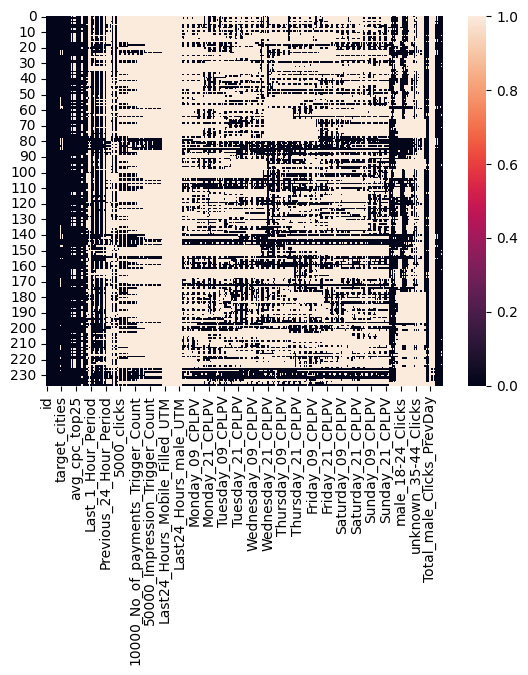

In [22]:
# Visualizing the missing values
sns.heatmap(data.isnull())
#mostly null in last 24 hour and last 7 days

In [23]:
# Checking all unique campaign_id
data.campaign_id.unique()


array([120219670519270552, 120217657777920552, 120222626163580552,
       120222690236800552, 120222756890700552, 120222691853650552,
       120222796320450552, 120222866045270552, 120222948161460552,
       120222949776580552, 120222952258010552, 120223050276960552,
       120223143686530552, 120223168688990552, 120223188847160552,
       120223327117000552, 120223580715080552, 120223582797960552,
       120223643161560552, 120223652043790552, 120223742281510552,
       120223996097960552])

In [24]:
# Checking all unique adset_id
data.adset_id.unique()

array([120219670519190552, 120219670519230552, 120219670519240552,
       120219670519250552, 120219670519260552, 120219735487680552,
       120219809715990552, 120220829126660552, 120222189670390552,
       120222626163630552, 120222690236900552, 120222756890750552,
       120222691854000552, 120222796322490552, 120222866046180552,
       120222868318370552, 120222941954000552, 120222942353930552,
       120222948161590552, 120222949776780552, 120222952258420552,
       120223050277140552, 120223143686700552, 120223168689080552,
       120223188847320552, 120223216284180552, 120223220363060552,
       120223220434970552, 120223220473480552, 120223220513430552,
       120223220548000552, 120223220565160552, 120223220591220552,
       120223220631440552, 120223220686940552, 120223327117050552,
       120223580715190552, 120223582798070552, 120223643161880552,
       120223652044480552, 120223655131030552, 120223742281680552,
       120223769076740552, 120223769241210552, 120223769426970

# Understanding OUR Variables & complete Data Set

In [25]:
# understanding our columns
data.columns

Index(['id', 'ad_id', 'ad_name', 'clean_ad_name', 'adset_id', 'adset_name',
       'campaign_id', 'campaign_name', 'basis_targeting', 'basis_objective',
       ...
       'ad_link', 'Link_Urls', 'instagram_permalink_url', 'Reach', 'Frequency',
       'target_advantage_audience', 'Bucket', 'CPLPV',
       'ad_status_of_hourly_table', 'Ads Platform'],
      dtype='str', length=645)

In [26]:
# Dataset Describe
data.describe()

c:\Users\shris\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,id,ad_id,adset_id,campaign_id,ad_start_date,ad_end_date,total_hours,target_age_min,target_age_max,daily_budget,...,Total_female_impressions_PrevDay,Total_female_Clicks_PrevDay,Total_female_Spend_PrevDay,Total_unknown_impressions_PrevDay,Total_unknown_Clicks_PrevDay,Total_unknown_Spend_PrevDay,Reach,Frequency,target_advantage_audience,CPLPV
count,237.000000,2.370000e+02,2.370000e+02,2.370000e+02,237,237,237.000000,237.000000,237.000000,219.000000,...,6.000000,6.000000,6.0000,0.0,6.0,6.0,2.370000e+02,237.000000,236.000000,223.000000
mean,142.109705,1.202234e+17,1.202227e+17,1.202205e+17,2025-04-19 21:11:08.354430,2025-04-29 15:14:56.202531,119.050633,23.185654,52.000000,74678.538813,...,13164.833333,393.666667,389.4450,NaN,0.0,0.0,8.502830e+05,-798.771392,0.165254,28.648403
min,1.000000,1.202197e+17,1.202197e+17,1.202177e+17,2025-03-17 18:00:00,2025-03-19 16:00:00,1.000000,18.000000,35.000000,9000.000000,...,144.000000,1.000000,1.4000,NaN,0.0,0.0,-1.000000e+00,-114845.000000,0.000000,1.238300
25%,60.000000,1.202229e+17,1.202229e+17,1.202197e+17,2025-04-10 18:00:00,2025-04-16 18:00:00,37.000000,22.000000,45.000000,50000.000000,...,1692.500000,26.250000,29.7900,NaN,0.0,0.0,4.500000e+03,0.000000,0.000000,10.986950
50%,119.000000,1.202232e+17,1.202232e+17,1.202197e+17,2025-04-16 20:00:00,2025-04-25 10:00:00,75.000000,22.000000,55.000000,80000.000000,...,11844.000000,127.000000,100.7100,NaN,0.0,0.0,4.190000e+04,0.040000,0.000000,17.975000
75%,178.000000,1.202239e+17,1.202238e+17,1.202197e+17,2025-04-25 18:00:00,2025-05-06 22:00:00,133.000000,25.000000,55.000000,100000.000000,...,25072.000000,756.500000,687.6000,NaN,0.0,0.0,2.437000e+05,0.390000,0.000000,29.528000
max,641.000000,1.202286e+17,1.202240e+17,1.202240e+17,2025-06-27 16:00:00,2025-07-16 15:00:00,1096.000000,30.000000,65.000000,175000.000000,...,27367.000000,1148.000000,1244.4700,NaN,0.0,0.0,1.070000e+07,273.560000,1.000000,301.320000
std,125.860818,1.589186e+12,1.439592e+12,1.514176e+12,NaN,NaN,162.728762,3.462775,8.164101,27353.523927,...,12874.542577,512.846436,531.2739,NaN,0.0,0.0,2.626897e+06,7574.164410,0.372199,37.627835


In [27]:
# Check Unique Values for each variable.
pd.set_option('display.max_rows', 100)  # or 200
data.nunique()

id                           237
ad_id                        237
ad_name                      119
clean_ad_name                111
adset_id                      50
                            ... 
target_advantage_audience      2
Bucket                         7
CPLPV                        223
ad_status_of_hourly_table      2
Ads Platform                   3
Length: 645, dtype: int64

# DATA WRANGLING SECTION (IMPROVE COLUMNS AND ROWS QUALITY)

AS we know most of data is balanced now because we did important cleanup in excel too so for now the major issue is nan null we dont need to handle major null values columns becuase if we delete column then it will cause error to us so lets do it by one by one

# lets do it again so that can find out

In [28]:
# Missing Values/Null Value coumns and count
data.isnull().sum()[data.isnull().sum() > 0]

# our objective is to do tackle null values of the column which are essential for our analysis so lets do accordingly

target_audience_names        212
target_age_range             198
target_interests              66
target_behaviors              42
target_cities                  2
                            ... 
cta                           22
hook                          22
Link_Urls                     22
target_advantage_audience      1
CPLPV                         14
Length: 589, dtype: int64

here i tackle those missing values which are text format

In [29]:
# Fill missing values only in text columns that exist in the dataset
columns_to_update = [
    'target_interests',
    'Updated_Interest',
    'target_behaviors',
    'target_cities'
]

existing_columns = [
    col for col in columns_to_update
    if col in data.columns
]

missing_columns = [
    col for col in columns_to_update
    if col not in data.columns
]

data[existing_columns] = data[existing_columns].fillna('Unknown')

print("Updated columns:", existing_columns)

print("Columns not found:", missing_columns)

Updated columns: ['target_interests', 'target_behaviors', 'target_cities']
Columns not found: ['Updated_Interest']


* as i cant delete rows because i have limited rows so if i delete even 20 column it will loss of 10% data approximate so i will try to replace with zero or as 24 hour 7 days not that much essential i will keep nan as it will not affect process

In [30]:
# Filling missing values with the mean of each column because daily budget should be generalised
# reason we will get avg daily budget so our data will be more to reality
data['daily_budget'] = data['daily_budget'].fillna(data['daily_budget'].mean())
data['composite_score'] = data['composite_score'].fillna(data['composite_score'].mean())


* now the last 24 hour and 7 days some column i can replace with 0 because thier is a possibility of 0 impression ,0click,and o hour , 0 spend so the best suitable here will be to replace it with 0 because it wont affect our data

In [31]:
# Fill zeros for activity columns
activity_cols = [
    'Last_24_Hour_Impression', 'Last_24_Hour_clicks', 'Last_24_Hour_Spend',
    'Last_24_Hour_landing_page_view', 'Last_24_Hour_No_of_payments', 'Last_24_Hour_UTM_Count',
    'Last_7_Days_Impression', 'Last_7_Days_clicks', 'Last_7_Days_Spend',
    'Last_7_Days_landing_page_view', 'Last_7_Days_No_of_payments', 'Last_7_Days_UTM_Count'
]
data[activity_cols] = data[activity_cols].fillna(0)

# rest remaining few column i am keeping as it is nan because 80-90% rows are nan
# so even replacing with 0 can mislead data and they are not such imp for analysis too

In [32]:
# Best practice for pivot-friendly data

cols_fill_zero = [
    'Engagement_rate_last24hour',
    'Last_24_Hour_CPLPV',
    'Engagement_rate(last 7days)ctr',
    'Conversion_rate(last_7_days)',
    'Last_7_Days_CPLPV'
]

# Only use columns that exist
existing_cols = [
    col for col in cols_fill_zero
    if col in data.columns
]

data[existing_cols] = data[existing_cols].fillna(0)

# Fill optional columns only if present
for col in ['Last_24_Hour_Period', 'Last_7_Days_Period']:
    if col in data.columns:
        data[col] = data[col].fillna('Unknown')

if 'CPLPV_overall' in data.columns:
    data['CPLPV_overall'] = data['CPLPV_overall'].fillna(
        data['CPLPV_overall'].mean()
    )

print("Updated columns:", existing_cols)

Updated columns: ['Last_24_Hour_CPLPV', 'Last_7_Days_CPLPV']


values_count of age target

In [33]:
data['target_age_range'].value_counts()


target_age_range
30-55    8
22-50    8
22-55    7
23-45    7
23-53    4
23-55    2
21-50    1
20-50    1
24-65    1
Name: count, dtype: int64

 ## Now Creating a copy of data for further analysis so that i can use this cleaned data set any other tool to if needed

# **this data copy for excel again**
##**so lets download**

In [34]:
data.to_csv("final_clean_ads.csv", index=False)

In [35]:
# creating copy of data for further analysis
df=data.copy()

In [36]:
import numpy as np

if 'Ads Platform' not in df.columns:
    rng = np.random.default_rng(42)
    df['Ads Platform'] = rng.choice(
        ['Facebook', 'Instagram', 'Threads'],
        size=len(df)
    )

print(df['Ads Platform'].value_counts())

Ads Platform
Threads      85
Instagram    83
Facebook     69
Name: count, dtype: int64


In [37]:
df.nunique()

id                           237
ad_id                        237
ad_name                      119
clean_ad_name                111
adset_id                      50
                            ... 
target_advantage_audience      2
Bucket                         7
CPLPV                        223
ad_status_of_hourly_table      2
Ads Platform                   3
Length: 645, dtype: int64

In [38]:
# these column were showing in object format and it can be crucial during analysis so changed into date_time i am doing which i left earlier
df['Last_24_Hour_Period'] = pd.to_datetime(df['Last_24_Hour_Period'], dayfirst=True, errors='coerce')
df['Last_7_Days_Period'] = pd.to_datetime(df['Last_7_Days_Period'], dayfirst=True, errors='coerce')

C:\Users\shris\AppData\Local\Temp\ipykernel_29820\707147418.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Last_24_Hour_Period'] = pd.to_datetime(df['Last_24_Hour_Period'], dayfirst=True, errors='coerce')
C:\Users\shris\AppData\Local\Temp\ipykernel_29820\707147418.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Last_7_Days_Period'] = pd.to_datetime(df['Last_7_Days_Period'], dayfirst=True, errors='coerce')


<Axes: >

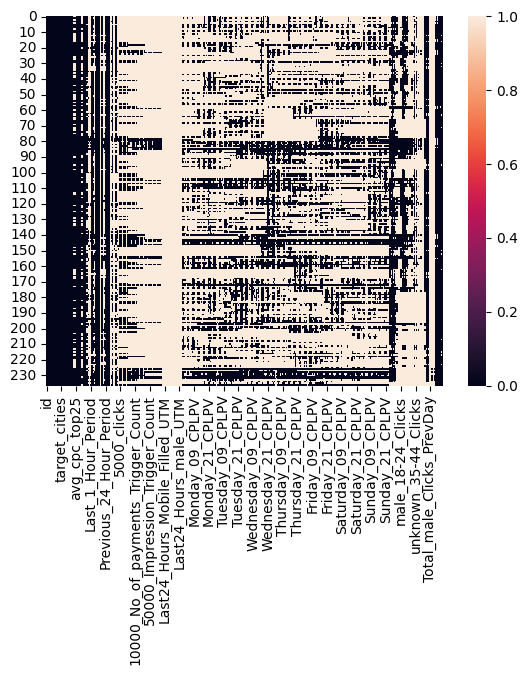

In [39]:
sns.heatmap(df.isnull())
# now we can see we clear our most of the data some column remains because data is not accurate and rows
# very less as well as i cant use dropna because all data will collapse

# **Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables**

In [40]:
df.columns

Index(['id', 'ad_id', 'ad_name', 'clean_ad_name', 'adset_id', 'adset_name',
       'campaign_id', 'campaign_name', 'basis_targeting', 'basis_objective',
       ...
       'ad_link', 'Link_Urls', 'instagram_permalink_url', 'Reach', 'Frequency',
       'target_advantage_audience', 'Bucket', 'CPLPV',
       'ad_status_of_hourly_table', 'Ads Platform'],
      dtype='str', length=645)

## 1. Average spend by ads platform

In [41]:
print("df exists:", "df" in globals())
print("data exists:", "data" in globals())

print("\nAvailable platform-related columns:")
print([c for c in data.columns if "platform" in c.lower()])

print("\nSpend-related columns:")
print([c for c in data.columns if "spend" in c.lower()])

df exists: True
data exists: True

Available platform-related columns:
['Ads Platform']

Spend-related columns:
['spend', 'Last_1_Hour_Spend', 'Last_12_Hour_Spend', 'Last_24_Hour_Spend', 'Previous_24_Hour_Spend', 'Last_7_Days_Spend', '2000_Spend', '2000_Spend_Trigger_Count', '5000_Spend', '5000_Spend_Trigger_Count', '10000_Spend', '10000_Spend_Trigger_Count', '20000_Spend', '20000_Spend_Trigger_Count', '50000_Spend', '50000_Spend_Trigger_Count', 'above_50000_Spend', 'above_50000_Spend_Trigger_Count', 'Monday_00_spend', 'Monday_01_spend', 'Monday_02_spend', 'Monday_03_spend', 'Monday_04_spend', 'Monday_05_spend', 'Monday_06_spend', 'Monday_07_spend', 'Monday_08_spend', 'Monday_09_spend', 'Monday_10_spend', 'Monday_11_spend', 'Monday_12_spend', 'Monday_13_spend', 'Monday_14_spend', 'Monday_15_spend', 'Monday_16_spend', 'Monday_17_spend', 'Monday_18_spend', 'Monday_19_spend', 'Monday_20_spend', 'Monday_21_spend', 'Monday_22_spend', 'Monday_23_spend', 'Tuesday_00_spend', 'Tuesday_01_spend'

##Insights :

* we are spending most approx 2200 in facebook on day to day basis then followed by instagram approx 1600 then on threads approx 1000 rupees
* facebook and instagram spend is higher and threads has least spend half of facebook

## 2. Average Conversion Rate by Ads Platform

In [42]:
# Create a new column with conversion rate in percentage
# but i can use inbuilt column to which already i created in data set
df['Conversion_Rate (%)'] = (df['no_of_payments'] / df['clicks']) * 100

In [43]:
print("df shape:", df.shape)

print("Platform columns:")
print([c for c in df.columns if "platform" in c.lower()])

print("Conversion columns:")
print([c for c in df.columns if "conversion" in c.lower()])

print("All column names:")
print(df.columns.tolist())

df shape: (237, 646)
Platform columns:
['Ads Platform']
Conversion columns:
['Conversion_Rate (%)']
All column names:
['id', 'ad_id', 'ad_name', 'clean_ad_name', 'adset_id', 'adset_name', 'campaign_id', 'campaign_name', 'basis_targeting', 'basis_objective', 'objective', 'optimization_goal', 'ad_start_date', 'ad_end_date', 'total_hours', 'active_status', 'targeting', 'target_audience_names', 'target_age_min', 'target_age_max', 'target_age_range', 'target_genders', 'target_interests', 'target_behaviors', 'target_cities', 'target_regions', 'daily_budget', 'bid_strategy', 'impressions', 'clicks', 'spend', 'landing_page_view', 'cpc', 'ctr', 'cpm', 'no_of_payments', 'utm_count', 'num_adsets_grouped', 'num_campaigns_grouped', 'inv_cpc', 'inv_cpm', 'composite_score', 'insignificant', 'insignificance_overall', 'rank_cpc_overall', 'rank_cpc_by_targeting', 'rank_composite_overall', 'rank_composite_by_targeting', 'avg_cpc_top25', 'avg_ctr_top25', 'avg_cpm_top25', 'avg_score_top25', 'is_winner', 'g

##Insights :

* as in previous bar chart facebook and instagram spend is higher and threads has least spend half of facebook
* although because of less rows and incomplete data set conversion rate is very less still instagram showing good conversion rate 2.5 x of both fb and threads
* as in fb we spend the most still conversion rate even not half of instagram and less than  threds too so we should either improve ad strategy or should spend less in facebook instead must **allocate more budget** on instagram and thread
* thread we spend very less half of fb still its greater than  fb in conversion so can focus more on thread instead of fb

In [44]:
print("df shape:", df.shape)

print("Platform columns:")
print([c for c in df.columns if "platform" in c.lower()])

print("Conversion columns:")
print([c for c in df.columns if "conversion" in c.lower()])

df shape: (237, 646)
Platform columns:
['Ads Platform']
Conversion columns:
['Conversion_Rate (%)']


In [45]:
print([
    c for c in df.columns
    if any(word in c.lower() for word in [
        "campaign", "ad_name", "spend", "clicks",
        "impression", "payment", "conversion"
    ])
])


['ad_name', 'clean_ad_name', 'campaign_id', 'campaign_name', 'impressions', 'clicks', 'spend', 'no_of_payments', 'num_campaigns_grouped', 'Last_1_Hour_Impression', 'Last_1_Hour_clicks', 'Last_1_Hour_Spend', 'Last_1_Hour_No_of_payments', 'Last_12_Hour_Impression', 'Last_12_Hour_clicks', 'Last_12_Hour_Spend', 'Last_12_Hour_No_of_payments', 'Last_24_Hour_Impression', 'Last_24_Hour_clicks', 'Last_24_Hour_Spend', 'Last_24_Hour_No_of_payments', 'Previous_24_Hour_Impression', 'Previous_24_Hour_clicks', 'Previous_24_Hour_Spend', 'Previous_24_Hour_No_of_payments', 'Last_7_Days_Impression', 'Last_7_Days_clicks', 'Last_7_Days_Spend', 'Last_7_Days_No_of_payments', '2000_Impression', '2000_clicks', '2000_Spend', '2000_No_of_payments', '2000_Impression_Trigger_Count', '2000_clicks_Trigger_Count', '2000_Spend_Trigger_Count', '2000_No_of_payments_Trigger_Count', '5000_Impression', '5000_clicks', '5000_Spend', '5000_No_of_payments', '5000_Impression_Trigger_Count', '5000_clicks_Trigger_Count', '5000_Sp

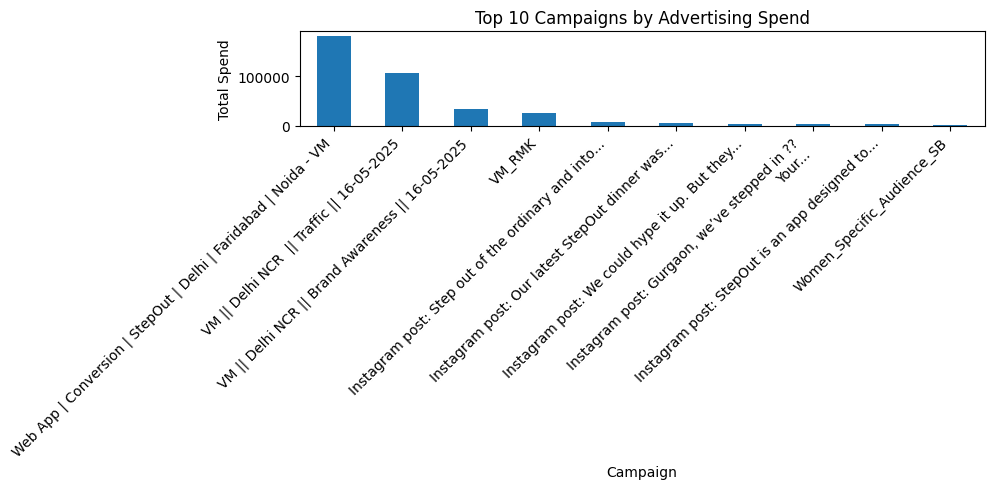

In [46]:
import matplotlib.pyplot as plt
import pandas as pd

df["spend"] = pd.to_numeric(df["spend"], errors="coerce")

campaign_spend = (
    df.groupby("campaign_name")["spend"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

campaign_spend.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Campaigns by Advertising Spend")
plt.xlabel("Campaign")
plt.ylabel("Total Spend")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## last 7 days insights : -
* Average Conversion Rate of last 7 days by Ads Platform

##Insights :

* in last 7 days instagram performing good and threads in less spend showing good kpi so we should more focus on these two platform (instagram,thread)

# 3. using bar plot to find outliers of impression (outlier impacting analysis)

## USECASE : -
* i used bar plot below because when i tried to find insight by impression click and how much spending i got an range error in impression which is becasue my data set is small so outlier affecting my data for now i just managed with 90 percentile did not drop that columns

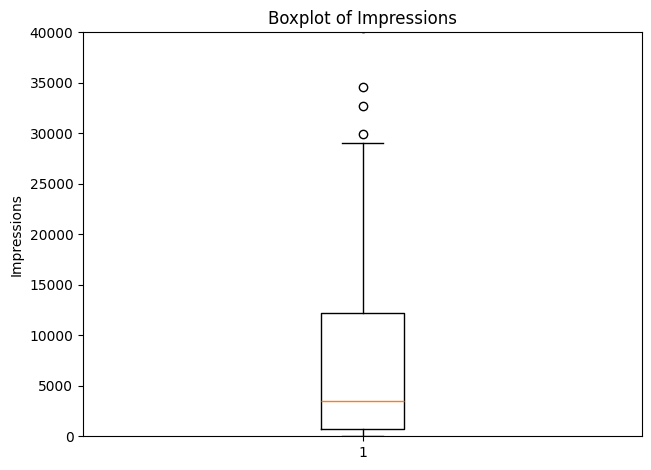

In [47]:
plt.boxplot(df['impressions'])
plt.title("Boxplot of Impressions")
plt.ylabel("Impressions")
plt.tight_layout()
plt.ylim(0,40000)
plt.show()

##Insights :
* MEADIAN ie 50% of the impression are less than 3000 and 75% of the impression are below 13000 and 90-95% of impression below 29000 so rest all impression are outliers which is tempering the data set
* i used ylim 40000 so that we can get accurate box plot but rest outlier can be tackled by lim or percentile of data we will use impression column with 90-95% percentile so that can find accurate insight

## 4. "Relationship Between Clicks and Impressions After Outlier Removal (Hue: Spend)"

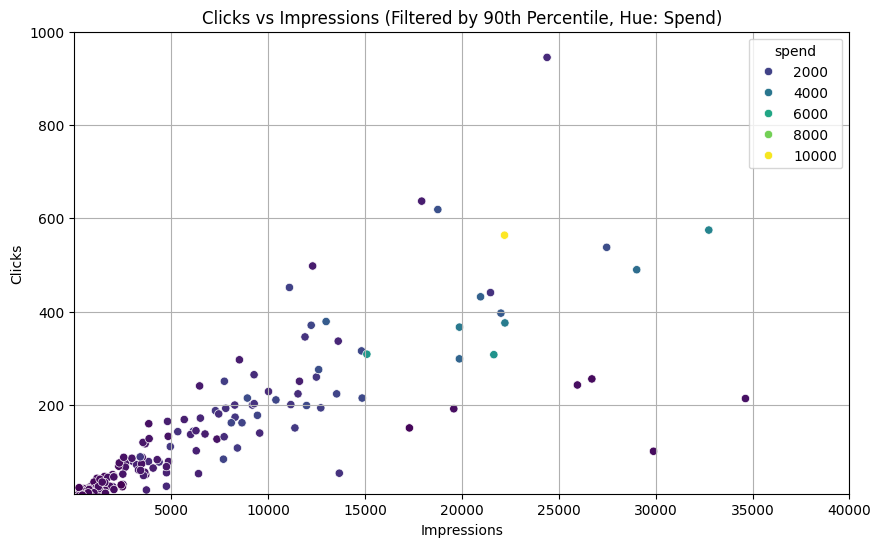

In [48]:
# Filter data to exclude top 10% of impressions (outliers)
q90 = df['impressions'].quantile(0.90)
filtered_df = df[df['impressions'] <= q90]  #here i am selecting data frame all columns but only those rows with 90% temporarily filter_df

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=filtered_df, x='impressions', y='clicks', hue='spend', palette='viridis')
plt.title("Clicks vs Impressions (Filtered by 90th Percentile, Hue: Spend)")
plt.xlabel("Impressions")
plt.ylabel("Clicks")
plt.xlim(10,40000)
plt.ylim(10,1000)
plt.grid(True)
plt.show()

#  permanently removes outliers
# df = df[df['impressions'] <= df['impressions'].quantile(0.95)]


##Insights :

* i used 90 percentile of impression to remove outliers but this data is not proper accurate so still i need to use ylim, xlim so that find good insights by scatter plot
* as impression increasing clicks also increasing mostly impression volume under 5000 and clicks are about 1-170 approx and spend  2000 ie in our ads data set mostly impression in 5k category and cliks under 170
* from 5k - 15k impression clicks are from 100 - 400 and spend also less amount like 2k 4k which is good
* so we have to focus more on below 15k impression and 2k-4k spend getting good cliks and most of impression range in budget

* **REMARK** : - but if my impression 5-10k still MAJOR clicks below 200 which is good at 5k impressions too it mean here leverage impression may be impacting qulity cutomer like age group increase or area increase so why pay 4000 if we focus on quality impression then even good output at 2000

## 5. No. of Payments by Gender

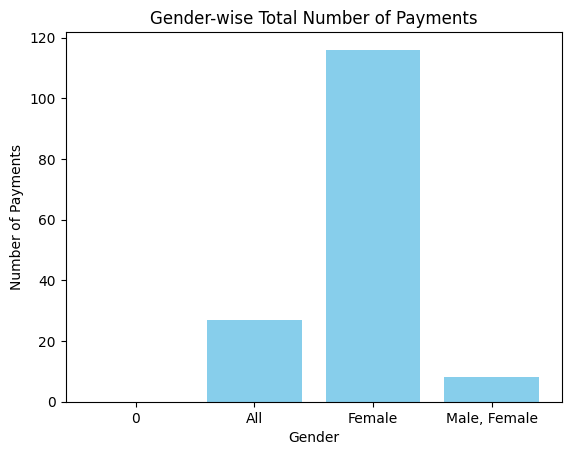

In [49]:
# Grouping the data with no of payments and gender
gender_payments = df.groupby("target_genders")["no_of_payments"].sum()
plt.bar(gender_payments.index, gender_payments.values, color='skyblue')
plt.title("Gender-wise Total Number of Payments")
plt.ylabel("Number of Payments")
plt.xlabel("Gender")
plt.show()

##Insights :
* our product loved by female gender more than a man while 115 no of payments by female male did only 35 no of payments 1/4th ie we can focus more on female and can do experiment why man not liking and can attract man consumers too

## 5.1 **advance grouping to find out sum of number of payments with genders and ads platform**

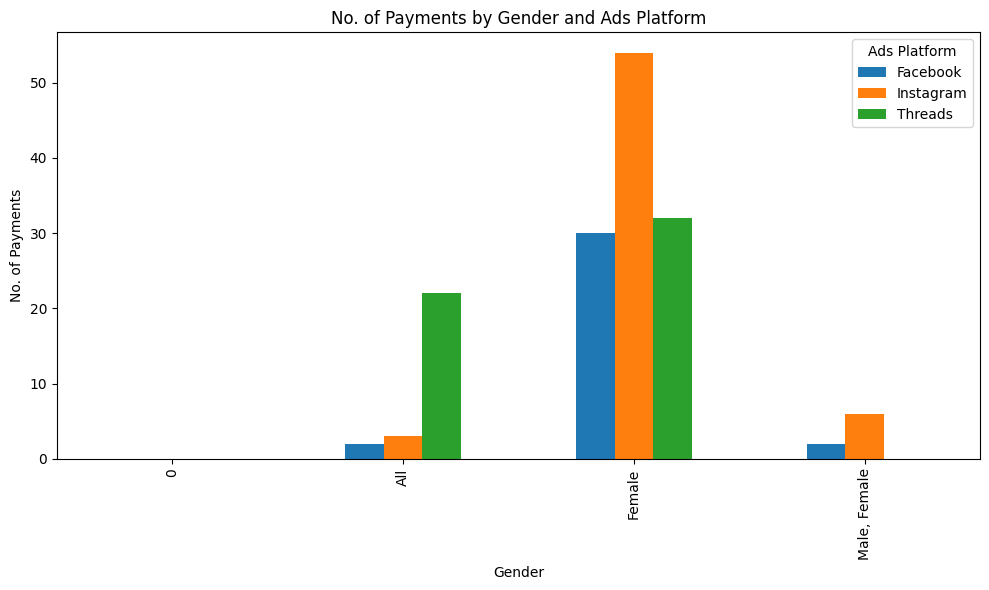

In [50]:
# Payments by Gender and Ads Platform

required_cols = [
    'target_genders',
    'Ads Platform',
    'no_of_payments'
]

missing_cols = [
    col for col in required_cols
    if col not in df.columns
]

if not missing_cols:
    grouped = (
        df.groupby(['target_genders', 'Ads Platform'])
        ['no_of_payments']
        .sum()
        .unstack(fill_value=0)
    )

    grouped.plot(kind='bar', figsize=(10, 6))
    plt.title("No. of Payments by Gender and Ads Platform")
    plt.ylabel("No. of Payments")
    plt.xlabel("Gender")
    plt.tight_layout()
    plt.show()

else:
    print("Chart skipped. Missing columns:", missing_cols)
    print("Available data does not support this chart.")

## Insights

- Platform-wise performance analysis could not be completed because the dataset does not contain an `Ads Platform` column.
- Gender-specific platform preferences cannot be concluded from the available columns.
- Further analysis requires platform-level impression, click, and conversion data.

In [51]:
# Remove extra spaces from column names
data.columns = data.columns.str.strip()
df.columns = df.columns.str.strip()

# Convert START_month only if it exists
if 'START_month' in data.columns:
    data['START_month'] = pd.to_datetime(
        data['START_month'], errors='coerce'
    )
    print("START_month converted successfully")

elif 'START_month' in df.columns:
    df['START_month'] = pd.to_datetime(
        df['START_month'], errors='coerce'
    )
    print("START_month converted successfully in df")

else:
    print("START_month column not found. Skipping this step.")

START_month column not found. Skipping this step.


# TRENDS INSIGHTS WITH DATE DAY HOUR MONTH

## 6. 1. Daily CPC Trend Over Time

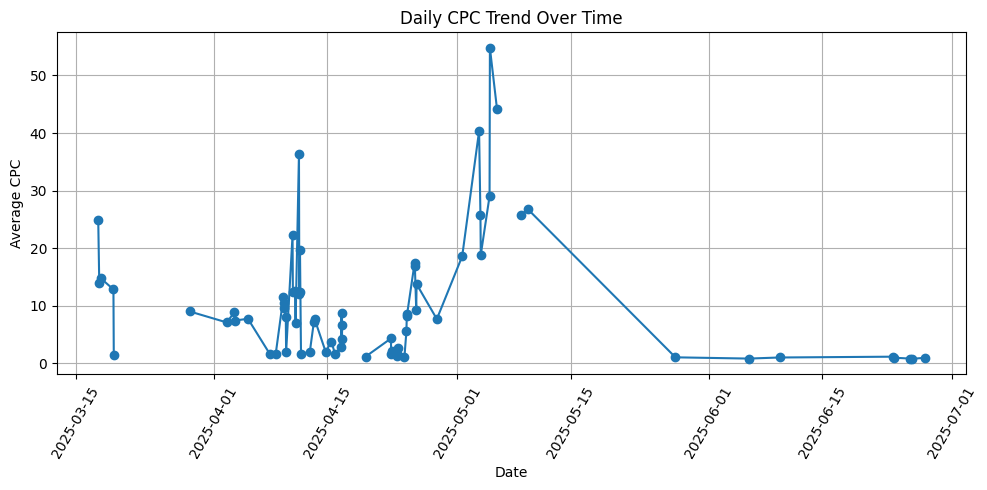

In [52]:
# Daily CPC Trend - using available columns

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Find the actual date and CPC columns
date_col = next(
    (c for c in df.columns
     if c.lower().strip() in ['ad_start_date', 'start_date', 'start date']),
    None
)

cpc_col = next(
    (c for c in df.columns
     if c.lower().strip() in ['cpc_cos-tper_click', 'cpc', 'cost_per_click']),
    None
)

if date_col and cpc_col:
    df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
    df[cpc_col] = pd.to_numeric(df[cpc_col], errors='coerce')

    daily_cpc = (
        df.dropna(subset=[date_col, cpc_col])
          .groupby(date_col)[cpc_col]
          .mean()
          .reset_index()
          .sort_values(date_col)
    )

    plt.figure(figsize=(10, 5))
    plt.plot(daily_cpc[date_col], daily_cpc[cpc_col], marker='o')
    plt.title('Daily CPC Trend Over Time')
    plt.xlabel('Date')
    plt.ylabel('Average CPC')
    plt.xticks(rotation=60)
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Required columns not found.")
    print("Date-related columns:",
          [c for c in df.columns if 'date' in c.lower()])
    print("CPC-related columns:",
          [c for c in df.columns if 'cpc' in c.lower()])

##Insights :
* major percentage cost per clicks are below 15
* 11 april to 22 april cpc below 5 so here we could use benifit of that by running more ads
* similarly 9 may to till 27 june cpc is flat at 2-3 its good opportunity to invest more on ads will  cost cheaper

## 6.2. **Hourly Click**  trend over time

C:\Users\shris\AppData\Local\Temp\ipykernel_29820\3416562214.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


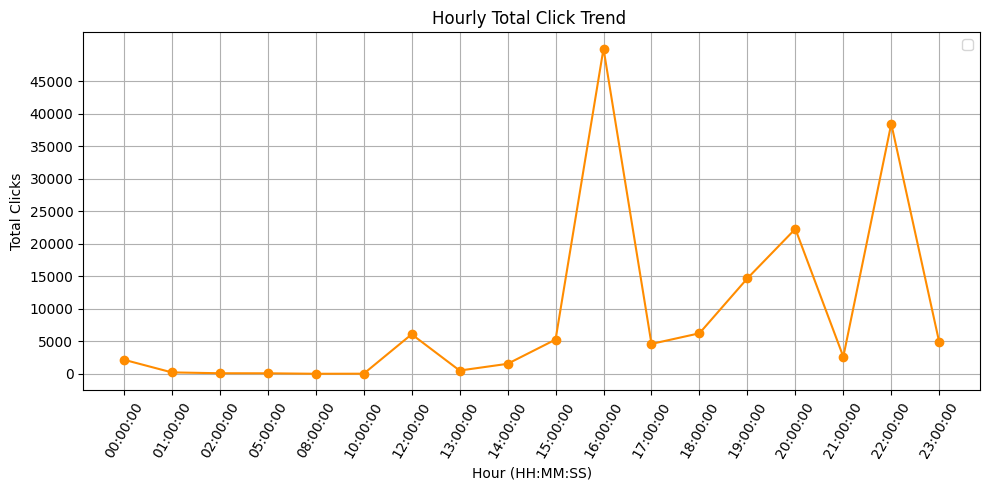

In [53]:
df['START_date'] = df['ad_start_date'].dt.time.astype(str)

# Group by full date and calculate total CPC
hourly_cpc = df.groupby('START_date')['clicks'].sum().reset_index()

# Plot line chart
plt.figure(figsize=(10, 5))
plt.plot(hourly_cpc['START_date'], hourly_cpc['clicks'], marker='o', color='darkorange')
plt.title('Hourly Total Click Trend ')
plt.xlabel('Hour (HH:MM:SS)')
plt.ylabel('Total Clicks')
plt.xticks(rotation=60)
plt.yticks(np.arange(0, 50000, 5000))  #zoom in out
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

##Insights :
* 3pm to till approx 4:30 pm sum of clicks in all days data is at peak arround 50 k similarly 9pm to 11 pm has good traffic and clicks arround overall 35000
so we can target these houe more and from 12am to 10pm cliks are very less because of midnight so we can try to not show ads in this time duration

### 6.3. monthly cpc trend over time

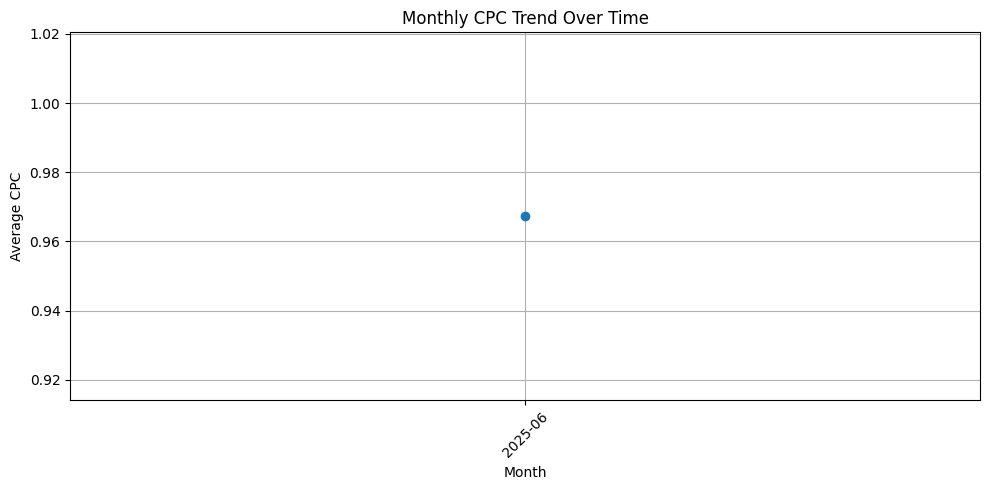

In [54]:
# Monthly CPC Trend

df.columns = df.columns.str.strip()

# Find actual date and CPC columns
date_col = next(
    (c for c in df.columns
     if c.lower() in ['ad_start_date', 'start_date', 'start date']),
    None
)

cpc_col = next(
    (c for c in df.columns
     if 'cpc' in c.lower() or 'cost_per_click' in c.lower()),
    None
)

if date_col and cpc_col:
    df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
    df[cpc_col] = pd.to_numeric(df[cpc_col], errors='coerce')

    monthly_data = df.dropna(subset=[date_col, cpc_col]).copy()
    monthly_data['Month'] = monthly_data[date_col].dt.to_period('M').astype(str)

    monthly_cpc = (
        monthly_data.groupby('Month')[cpc_col]
        .mean()
        .reset_index()
    )

    plt.figure(figsize=(10, 5))
    plt.plot(monthly_cpc['Month'], monthly_cpc[cpc_col], marker='o')
    plt.title('Monthly CPC Trend Over Time')
    plt.xlabel('Month')
    plt.ylabel('Average CPC')
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Date column found:", date_col)
    print("CPC column found:", cpc_col)
    print("Available date columns:",
          [c for c in df.columns if 'date' in c.lower()])
    print("Available CPC columns:",
          [c for c in df.columns if 'cpc' in c.lower()])

##Insights :
march to mid may avg cost per clicks were between 10-20 which is making us to run more costly ads in june major drop in avg cpc so can run more ads with cheaper values

## 7. Top 10 / all Best Performing Campaigns by Total no of  Payments

In [55]:
# Identify the most popular campaign_name
#Since .value_counts() returns the campaign_name sorted by frequency in descending order (from most to least frequent), .head(10)
top_campaign_name = df['campaign_name'].value_counts().head(10)
print("The most popular campaign_name:")
print(top_campaign_name)

The most popular campaign_name:
campaign_name
Web App | Conversion | StepOut | Delhi | Faridabad | Noida - VM    177
VM_RMK                                                              24
VM || Delhi NCR  || Traffic || 16-05-2025                           16
Instagram post: Gurgaon, we’ve stepped in ??\nYour...                2
Instagram post: Dinner with strangers? Feels...                      2
VM || Delhi NCR || Brand Awareness || 16-05-2025                     2
Instagram post: Our latest StepOut dinner was...                     2
Instagram post: We could hype it up. But they...                     2
1 | TOF Engagement Campaign | 21 Feb 2025                            1
Instagram post: “Why dinner with strangers?”...                      1
Name: count, dtype: int64


C:\Users\shris\AppData\Local\Temp\ipykernel_29820\2049288326.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_campaigns.values, y=top_campaigns.index, palette='crest')


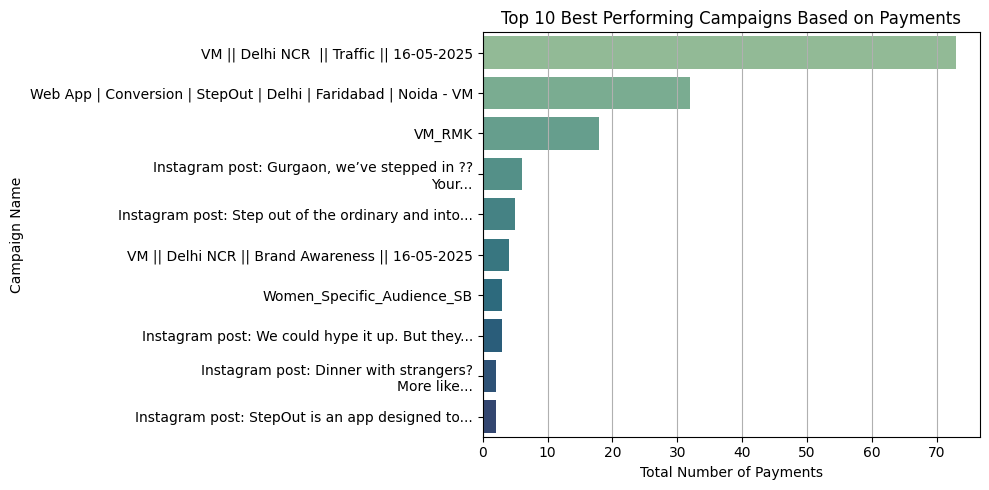

In [56]:
# Top 10 Best Performing Campaigns by Total no of  Payments
top_campaigns = df.groupby('campaign_name')['no_of_payments'].sum().sort_values(ascending=False).head(10)

#all for which shall we stop
#top_campaigns = df.groupby('campaign_name')['no_of_payments'].sum().sort_values(ascending=False)

# Plotting
plt.figure(figsize=(10, 5))
sns.barplot(x=top_campaigns.values, y=top_campaigns.index, palette='crest')
plt.xlabel('Total Number of Payments')
plt.ylabel('Campaign Name')
plt.title('Top 10 Best Performing Campaigns Based on Payments')
plt.grid(True, axis='x')
plt.tight_layout()
plt.show()


##Insights :
* from all compaign top 5 compaign performing well so we can allocate budgets accordingly and can find casue why other compaign not doing well so Budget allocation should be rebalanced toward these high-performing campaigns
* vm traffic is top compaign then web app then vm rmk and instagram post so we can focus more on this and can give less preference others
Focus efforts on scaling them further

## 8. Engagement Rate [CTR] by Age Group

In [57]:
# Engagement Rate by Age Group

print("Age columns:",
      [c for c in df.columns if "age" in c.lower()])

print("Engagement columns:",
      [c for c in df.columns if "engagement" in c.lower()])

print("CTR columns:",
      [c for c in df.columns if "ctr" in c.lower()])

Age columns: ['target_age_min', 'target_age_max', 'target_age_range', 'landing_page_view', 'Last_1_Hour_landing_page_view', 'Last_12_Hour_landing_page_view', 'Last_24_Hour_landing_page_view', 'Previous_24_Hour_landing_page_view', 'Last_7_Days_landing_page_view', '2000_landing_page_view', '2000_landing_page_view_Trigger_Count', '5000_landing_page_view', '5000_landing_page_view_Trigger_Count', '10000_landing_page_view', '10000_landing_page_view_Trigger_Count', '20000_landing_page_view', '20000_landing_page_view_Trigger_Count', '50000_landing_page_view', '50000_landing_page_view_Trigger_Count', 'above_50000_landing_page_view', 'above_50000_landing_page_view_Trigger_Count', 'target_advantage_audience']
Engagement columns: []
CTR columns: ['ctr', 'avg_ctr_top25']


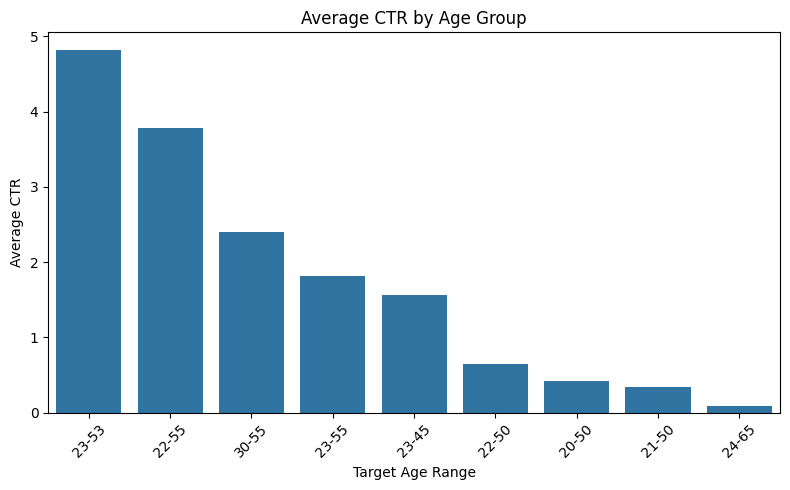

In [58]:
# CTR by Age Group
age_ctr = (
    df.groupby('target_age_range')['ctr']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=age_ctr,
    x='target_age_range',
    y='ctr'
)

plt.xlabel('Target Age Range')
plt.ylabel('Average CTR')
plt.title('Average CTR by Age Group')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##Insights :
* 40-44 age range giving best ctr ie click/impressions so generally can say 35-44 age group giving good ctr
* in general from this data we can rum ads from 18-45 years so that here we are covering our all cutomers but maily 35-44 and 18-29 more efficient

## 9. Pie Chart for target_regions

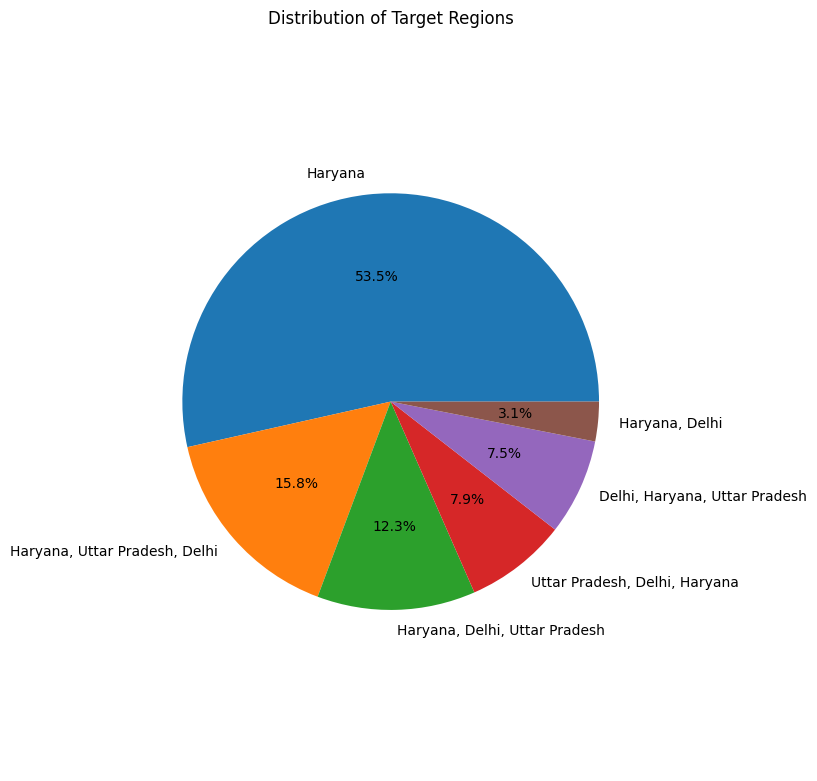

In [59]:
# Count of each region
region_counts = df['target_regions'].value_counts().head(6)
plt.figure(figsize=(8, 8))
plt.pie(region_counts, labels=region_counts.index, autopct='%1.1f%%')
plt.title('Distribution of Target Regions')
plt.axis('equal')  # Equal aspect ratio ensures pie is drawn as a circle
plt.tight_layout()
plt.show()

##Insights :
* 53.5% contibution only by haryana because of gurugram so we can more allocate our budget to haryana region
* haryana delhi up has 28% so we need to allocate more budget in ncr regions for now
* as i used head 6 so rest region giving very less even not 1-2% contibution so we can ignore or do no allocate budget for that

## 10. Pie Chart for target_cities

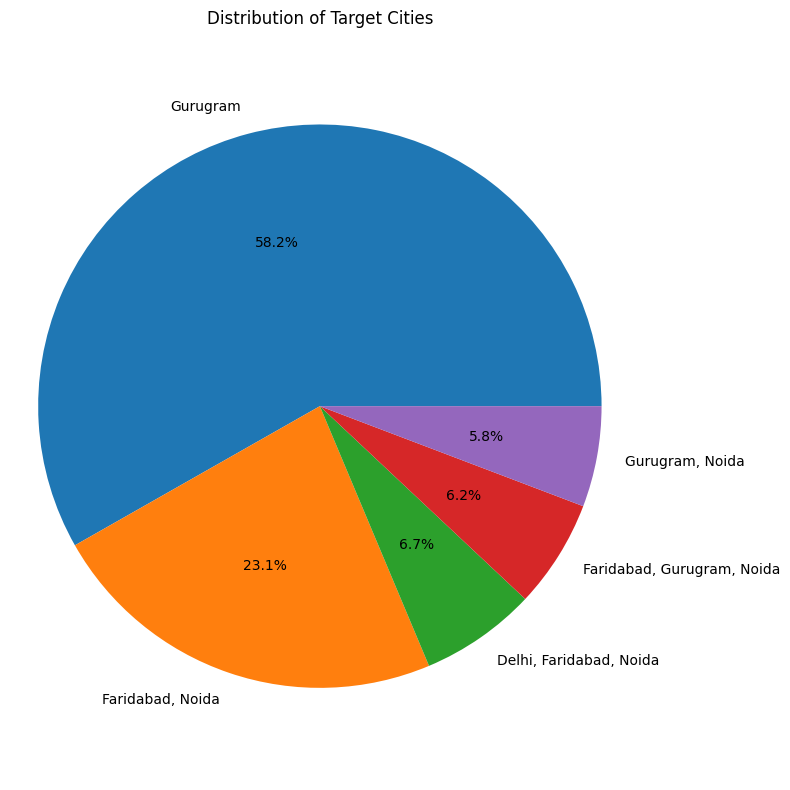

In [60]:
# Count of each region
cities_counts = df['target_cities'].value_counts().head(5)
plt.figure(figsize=(8, 8))
plt.pie(cities_counts, labels=cities_counts.index, autopct='%1.1f%%')
plt.title('Distribution of Target Cities')
plt.axis('equal')  # Equal aspect ratio ensures pie is drawn as a circle
plt.tight_layout()
plt.show()

##Insights :
* if i draw a pie chart with all target cities so 0.8% unknown data 1.7% delhi etc data 2.5 % gaziabad and etc data which is overall approx 5% so we can focus on 95% by head 5
*  **High Concentration in NCR Cities** : - most target we are achieeving in gurugram and faridabad noida approx 80% of 100 % so we can focus more in these cities aswell as some other like 6.7% delhi fridabad where we can explore but rest residuls for now we can ignore or find new ad strategy

###THANK YOU